# 1. 环境搭建
## 1.1 自然语言处理任务
### 1)常见自然语言处理任务

* 情感分析(sentiment-analysis):对给定的文本分析其情感极性<br>
* 文本生成(text-generation):根据给定的文本进行生成<br>
* 命名实体识别(ner):标记句子中的实体<br>
* 阅读理解(question-answering):给定上下文与问题，从上下文中抽取答案<br>
* 掩码填充(fil-mask):填充给定文本中的掩码词<br>
* 文本摘要(summarization):生成一段长文本的摘要<br>
* 机器翻译(translation):将文本翻译成另一种语言<br>
* 特征提取(feature-extraction):生成给定文本的张量表示<br>
* 对话机器人(conversional):根据用户输入文本，产生回应，与用户对话<br>



## 1.2 HuggingFace介绍
官方网址: https://huggingface.co/	<br>
HuggingFace 是一个开源社区，提供了开源的 AI 研发框架、工具集、可在线加载的数据集仓库和预训练模型仓库。<br>
HuggingFace 提出了一套可以依照的标准研发流程，HaggingFace 把 AI 项目的研发大致分为以下几个部分：<br>
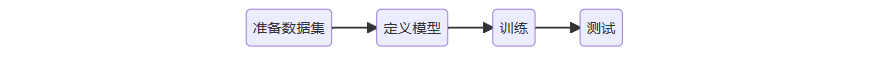<br>
针对标准流程的各个节点，HuggingFace 都提供了许多工具，能够帮助研发人员快速实施。<br>
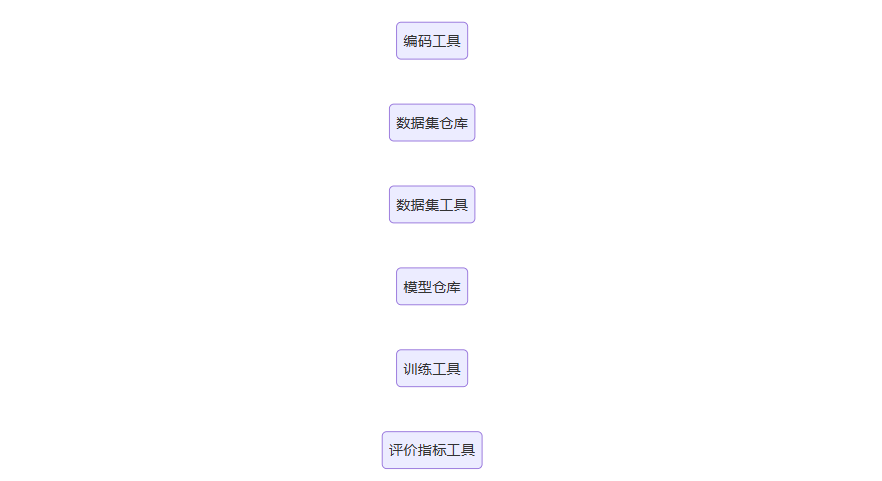<br>

### 1）Transformers简单介绍

Transformers 是一个用来构建 NLP 应用库

a) HuggingFace出品，当下最热、最常使用的自然语言处理工具包之一，不夸张的说甚至没有之一	<br>
b) 实现了大量的基于Transformer架构的主流预训练模型，不局限于自然语言处理模型，还包括图像、音频以及多模态的模型<br>
c) 提供了海量的预训练模型与数据集，同时支持用户自行传，社区完善，文档全面，三两行代码便可快速实现模型训练推理，上手简单<br>



### 2）Transformers及相关库

* Transformers:核心库，模型加载、模型训练、流水线等<br>
* Tokenizer:分词器，对数据进行预处理，文本到token序列的互相转换<br>
* Datasets:数据集库，提供了数据集的加载、处理等方法<br>
* Evaluate:评估函数，提供各种评价指标的计算函数<br>
* PEFT:高效微调模型的库，提供了几种高效微调的方法，小参数量撬动大模型<br>
* Accelerate:分布式训练，提供了分布式训练解决方案，包括大模型的加载与推理解决方案<br>
* Optimum:优化加速库，支持多种后端，如Onnxruntime、OpenVino等<br>
* Gradio:可视化部署库，几行代码快速实现基于Web交互的算法演示系统<br>

https://mp.weixin.qq.com/s?__biz=MjM5MzQ5NTU0Mw==&mid=2455052223&idx=1&sn=71a04ed4dab98ea327a30a3a3d8d4e0f&scene=21#wechat_redirect

### 3) Transformers安装

In [ ]:
#创建虚拟环境
# conda create -n python-transformers python=3.11
#激活虚拟环境：
# conda activate python-transformers
#使用以下命令安装 Transformers：
# pip install transformers==4.47.1    pytorch  版本大于2.6才行
# pip install datasets==3.2.0
# pip install evaluate==0.4.3
# pip install peft==0.14.0
# pip install accelerate==1.2.1

In [ ]:
from transformers import AutoModel, AutoTokenizer
# huggingface指定模型下载缓存目录
model = AutoModel.from_pretrained(
    "uer/roberta-base-finetuned-dianping-chinese",
    cache_dir="D:/models/huggingface_cache"  # 指定下载缓存路径
)

tokenizer = AutoTokenizer.from_pretrained(
    "uer/roberta-base-finetuned-dianping-chinese",
    cache_dir="D:/models/huggingface_cache"
)


# modelscope download --model Qwen/Qwen3-Next-80B-A3B-Thinking README.md --local_dir ./dir
#模型下载
from modelscope import snapshot_download
model_path = snapshot_download(
    model_id='Qwen/Qwen3-Next-80B-A3B-Thinking',
    cache_dir='D:/models/Qwen3-Next-80B-A3B-Thinking')



# 2. Tonkenizer
## 2.1 Tokenizer简介

数据预处理<br>

* 分词:使用分词器对文本数据进行分词(字、字词);<br>
* 构建词典:根据数据集分词的结果，构建词典映射(这一步并不绝对，如果采用预训练词向量，词典映射要根据词向量文件进行处理);<br>
* 数据转换:根据构建好的词典，将分词处理后的数据做映射，将文本序列转换为数字序列;<br>
* 数据填充与截断:在以batch输入到模型的方式中，需要对过短的数据进行填充，过长的数据进行截断保证数据长度符合模型能接受的范围，同时batch内的数据维度大小一致。
<br>


## 2.2 Tokenizer基本使用方法
### 1) 句子分词

https://mp.weixin.qq.com/s/9pzYEmGTg7t4UksQnd_lKA

In [ ]:
from transformers import AutoTokenizer
#vocab.txt是词表文件（文件中是保留符号和单个汉字索引，字符），每个token在词表中都有唯一的ID号。不同模型的词表文件会因为设置的规则不同导致内容不同，所以相同的文本序列调用不同模型的tokenizer会产生不同的整数索引。预训练模型与tokenizer必须使用相同的vocab文件和配置文件才能使输入文本序列满足模型的输入要求。

# 模型加载
tokenizer = AutoTokenizer.from_pretrained(r"D:\vs_code\transformers-code\models\uer\roberta-base-finetuned-dianping-chinese")

# 句子分词
sen = "真术相成，值得信赖！" 
tokens = tokenizer.tokenize(sen)
tokens

### 2) 查看词典

In [2]:
# 查看词典
tokenizer.vocab 

{'##綽': 18269,
 '##锟': 20290,
 '洁': 3815,
 '##way': 8824,
 'path': 12443,
 '馅': 7666,
 '##lus': 11131,
 '##嚥': 14767,
 '断': 3171,
 '台': 1378,
 '茎': 5749,
 'pixnetfacebookyahoo': 12047,
 '騁': 7696,
 'leonnhurt': 13160,
 '映': 3216,
 '##伤': 13896,
 'emily': 12384,
 '吵': 1427,
 'bell': 9993,
 '##mb': 8517,
 '原': 1333,
 '赁': 6595,
 '##忤': 15625,
 '挂': 2899,
 'ᵐ': 334,
 '胃': 5517,
 'icp': 9658,
 '306': 10576,
 '##盱': 17739,
 '##gc': 10817,
 '##簪': 18140,
 '薪': 5959,
 'qe': 11534,
 '##star': 10297,
 '##问': 20366,
 '燻': 4252,
 '##使': 13943,
 '##饌': 20695,
 '谣': 6469,
 'vi': 10138,
 '##蔺': 18983,
 '灼': 4133,
 '##rian': 12475,
 '##╠': 13590,
 '″': 346,
 '勢': 1248,
 '資': 6536,
 '[unused64]': 64,
 '嘱': 1671,
 '雛': 7428,
 '05': 8137,
 '##mond': 11423,
 '##志': 15619,
 '##耷': 18514,
 '##蹑': 19749,
 '##邹': 19998,
 '##甘': 17548,
 '樂': 3556,
 '磨': 4836,
 'i3': 12224,
 '轴': 6766,
 '◠': 476,
 '枝': 3363,
 '##］': 21091,
 '弊': 2464,
 '##蛆': 19082,
 '##态': 15635,
 'tokyo': 10357,
 '琉': 4417,
 '##圳': 14823,
 '

### 3) 查看词典的数量

In [3]:
# 查看词典的数量
tokenizer.vocab_size

21128

### 4) 索引转换

In [3]:
# 将词序列转换为id序列
ids = tokenizer.convert_tokens_to_ids(tokens)
ids

[4696, 3318, 4685, 2768, 8024, 966, 2533, 928, 6609, 8013]

In [4]:
# 将id序列转换为token序列
tokens = tokenizer.convert_ids_to_tokens(ids)
tokens

['真', '术', '相', '成', '，', '值', '得', '信', '赖', '！']

In [5]:
# 将token序列转换为string
str_sen = tokenizer.convert_tokens_to_string(tokens)
str_sen

'真 术 相 成 ， 值 得 信 赖 ！'

In [6]:
# 更便捷的实现方式
ids = tokenizer.encode(sen)	
ids

[101, 4696, 3318, 4685, 2768, 8024, 966, 2533, 928, 6609, 8013, 102]

In [7]:
# 将id序列转换为字符串，又称之为解码
str_sen = tokenizer.decode(ids)
str_sen

'[CLS] 真 术 相 成 ， 值 得 信 赖 ！ [SEP]'

In [8]:
# 不希望这个两个占位词出来
ids = tokenizer.encode(sen, add_special_tokens=False)	
ids

[4696, 3318, 4685, 2768, 8024, 966, 2533, 928, 6609, 8013]

In [9]:
# 将id序列转换为字符串，又称之为解码
str_sen = tokenizer.decode(ids, skip_special_tokens=False)
str_sen

'真 术 相 成 ， 值 得 信 赖 ！'

### 5) 填充和截断

In [10]:
# 填充
ids = tokenizer.encode(sen, padding='max_length', max_length=15)
ids

[101, 4696, 3318, 4685, 2768, 8024, 966, 2533, 928, 6609, 8013, 102, 0, 0, 0]

In [11]:
# 截断
ids = tokenizer.encode(sen, max_length=5, truncation=True)
ids

[101, 4696, 3318, 4685, 102]

### 6) 处理batch数据

In [12]:
sens = [
    '真术相成真的很好',
    '真术相成，值得信赖',
    '期待我们在真术相成相遇，一起变得更美好'
]
res = tokenizer(sens, max_length=15, padding='max_length', truncation=True)
res

{'input_ids': [[101, 4696, 3318, 4685, 2768, 4696, 4638, 2523, 1962, 102, 0, 0, 0, 0, 0], [101, 4696, 3318, 4685, 2768, 8024, 966, 2533, 928, 6609, 102, 0, 0, 0, 0], [101, 3309, 2521, 2769, 812, 1762, 4696, 3318, 4685, 2768, 4685, 6878, 8024, 671, 102]], 'token_type_ids': [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]}

input_ids:是单词在词典中的编码<br>
token_type_ids:区分两个句子的编码（上句全为0，下句全为1）<br>
attention_mask:指定对哪些词进行self-Attention操作<br>

# 3. Model
## 3.1 Model 简介

### 1)Transformer

* 原始的Transformer为编码器(Encoder)、解码器(Decoder)模型	<br>
* Encoder部分接收输入并构建其完整特征表示，Decoder部分使用Encoder的编码结果以及其他的输入生成目标序列<br>
* 无论是编码器还是解码器，均由多个TransformerBlock堆叠而成	<br>
* TransformerBlock由注意力机制(Attention)和FFN组成	<br>



### 2)注意力机制
<br>
* 注意力机制的使用是Transformer的一个核心特性，在计算当前词的特征表示时，可以通过注意力机制有选择性的告诉模型要使用哪些上下文<br>

![image-20240712154939567](images/image-20240712154939567.png)




### 3)模型类型
<br>
* 编码器模型:自编码模型，	<br>
  使用Encoder，拥有双向的注意力机制，即计算每一个词的特征时都看到完整上下文<br>
* 解码器模型:自回归模型，	<br>
  使用Decoder，拥有单向的注意力机制，即计算每一个词的特征时都只能看到上文，无法看到下文<br>
* 编码器解码器模型:序列到序列模型，	<br>
  使用Encoder+Decoder，Encoder部分使用双向的注意力，Decoder部分使用单向注意力<br>

<img src="images/image-20240712155013654.png"  />

<br>
<br>

<img src="images/image-20240712155038564.png">

<br>
<br>

* GPT

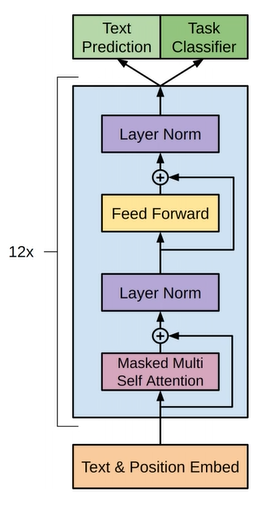

* Bert


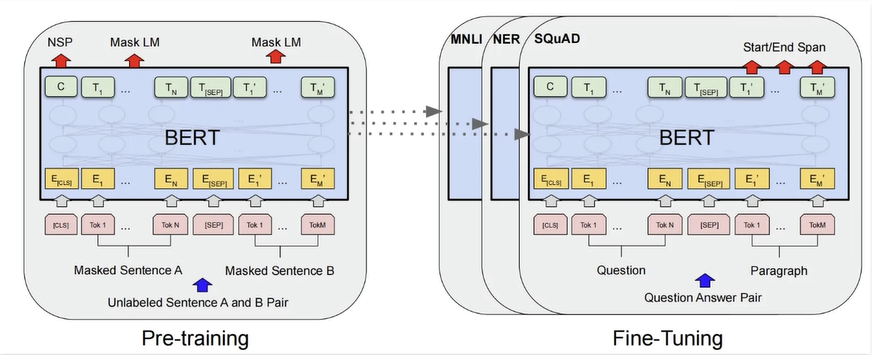
## 3.2 Model Head

### 1) 什么是Model Head

Model Head 是连接在模型后的层，通常为1个或多个全连接层<br>
Model Head 将模型的编码的表示结果进行映射，以解决不同类型的任务<br>

<img src="images/image-20240712155136619.png" />



### 2) Transformers中的Model Head
Model head是模型架构中用于处理特定任务的关键组件，它负责将模型编码的表示映射到任务所需的输出格式：（它们在预训练模型的基础上添加了一层或多层额外的网络结构，以适应任务需求，比如针对特定任务设计分类、问答或生成）<br>

* Model(模型本身，只返回编码结果)<br>
* ForCausalLM: 这是带有因果语言建模头的模型，通常用于解码器（Decoder）类型的任务。这种类型的任务包括文本生成或文本完成，其中生成的每个新词都依赖于之前生成的所有词。<br>
* ForMaskedLM: 这是带有掩码语言建模头的模型，用于编码器（Encoder）类型的任务。这种任务涉及预测文本中被掩盖或隐藏的词，BERT模型就是这种类型的一个例子<br>
* ForSeq2SeqLM: 这是带有序列到序列语言建模头的模型，适用于需要编码器和解码器共同工作的任务，如机器翻译或文本摘要。<br>
* ForMultipleChoice: 这是用于多项选择任务的模型，它处理包含多个候选答案的输入，并预测正确答案的索引。<br>
* ForQuestionAnswering: 这是问答任务的模型，它从给定的文本中抽取答案。这种模型通常包括一个编码器来理解问题和上下文，然后是一个答案抽取机制。<br>
* ForSequenceClassification: 这是用于文本分类任务的模型，它将整个输入序列映射到一个或多个标签。例如，情感分析或主题分类。<br>
* ForTokenClassification: 这是用于标记分类任务的模型，如命名实体识别（NER），它将序列中的每个标记映射到一个预定义的标签。<br>
* ...

## 3.3 Model 基本使用方法
### 1) 加载模型

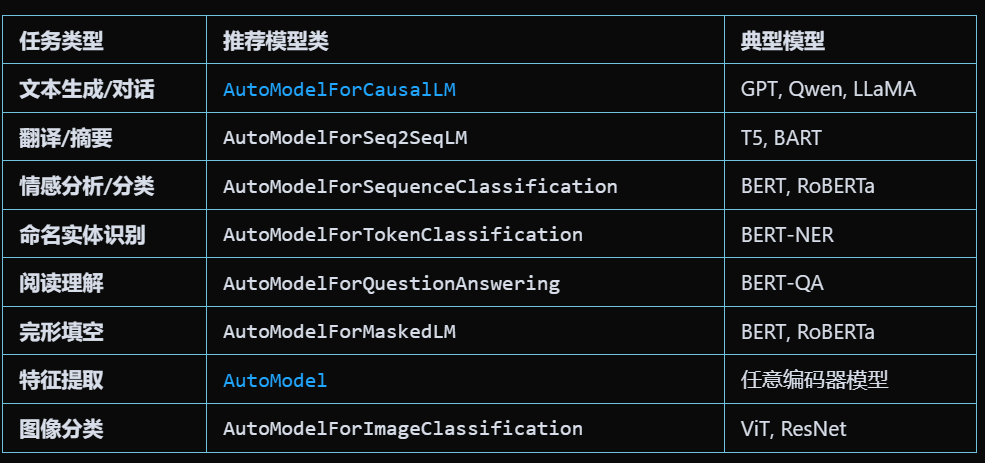


In [ ]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

sen = '真术相成真好!'
tokenizer = AutoTokenizer.from_pretrained(r"/teacher_train/model/rbt3/")
inputs = tokenizer(sen, return_tensors='pt')

clz_model = AutoModelForSequenceClassification.from_pretrained(r"/teacher_train/model/rbt3/")

# 使用模型
result = clz_model(**inputs)
print(result)



#获取模型参数
print(model.config)

# 也可以使用AutoConfig方式来获取参数
from transformers import AutoConfig
config = AutoConfig.from_pretrained(r"/teacher_train/model/rbt3/")
print(config)

### 2) 修改模型输出的结果个数

In [4]:
# 修改模型输出的结果个数
clz_model = AutoModelForSequenceClassification.from_pretrained(r"D:\vs_code\transformers-code\models\hfl\rbt3", num_labels=10)
clz_model(**inputs)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at D:\vs_code\transformers-code\models\hfl\rbt3 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


SequenceClassifierOutput(loss=None, logits=tensor([[ 0.3309,  0.5872, -0.7048, -0.2902, -0.8218,  0.0895,  0.5136,  0.3417,
         -0.3800,  0.5014]], grad_fn=<AddmmBackward0>), hidden_states=None, attentions=None)

### 5) 模型保存和加载

In [5]:
# 将类别为10的模型保存到本地
clz_model.save_pretrained("./clz_model")

In [8]:
from transformers import AutoModelForSequenceClassification
# 加载本地模型
clz_model = AutoModelForSequenceClassification.from_pretrained("./clz_model")
clz_model

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(21128, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0): BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, element

In [ ]:
# 使用模型
res = clz_model(**inputs)

SequenceClassifierOutput(loss=None, logits=tensor([[ 0.3309,  0.5872, -0.7048, -0.2902, -0.8218,  0.0895,  0.5136,  0.3417,
         -0.3800,  0.5014]], grad_fn=<AddmmBackward0>), hidden_states=None, attentions=None)

In [ ]:
'''
KV Cache 主要用于:
AutoModelForCausalLM (因果语言模型,如 GPT)
AutoModelForSeq2SeqLM (序列到序列模型,如 T5)
生成类模型可以查看kvcache
'''

from transformers import AutoModelForCausalLM, AutoTokenizer

# 加载生成式模型
model = AutoModelForCausalLM.from_pretrained("./your_model")
tokenizer = AutoTokenizer.from_pretrained("./your_model")

# 准备输入
inputs = tokenizer("你好,今天天气", return_tensors="pt")

# 方法1: 在forward时返回past_key_values
outputs = model(**inputs, use_cache=True)

# 查看KV Cache
print("past_key_values:", outputs.past_key_values)
print("KV Cache 层数:", len(outputs.past_key_values))
print("第一层的key shape:", outputs.past_key_values[0][0].shape)
print("第一层的value shape:", outputs.past_key_values[0][1].shape)

### 6) 模型的两种推理方式

In [ ]:
import os
os.environ['HF_ENDPOINT'] = 'https://hf-mirror.com'
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained("/teacher_train/model/qwen2.5-3B-Instruct")
model = AutoModelForCausalLM.from_pretrained("/teacher_train/model/qwen2.5-3B-Instruct",device_map="auto")


inputs = tokenizer("Hello, how are you?", return_tensors="pt").to(model.device)

outputs = model.generate(**inputs, max_new_tokens=100)

output_text = tokenizer.decode(
    outputs[0], 
    skip_special_tokens=False  # <--- 关键！设为 False 就能看到所有特殊标记
)
print(f"完整生成结果:\n{output_text}")

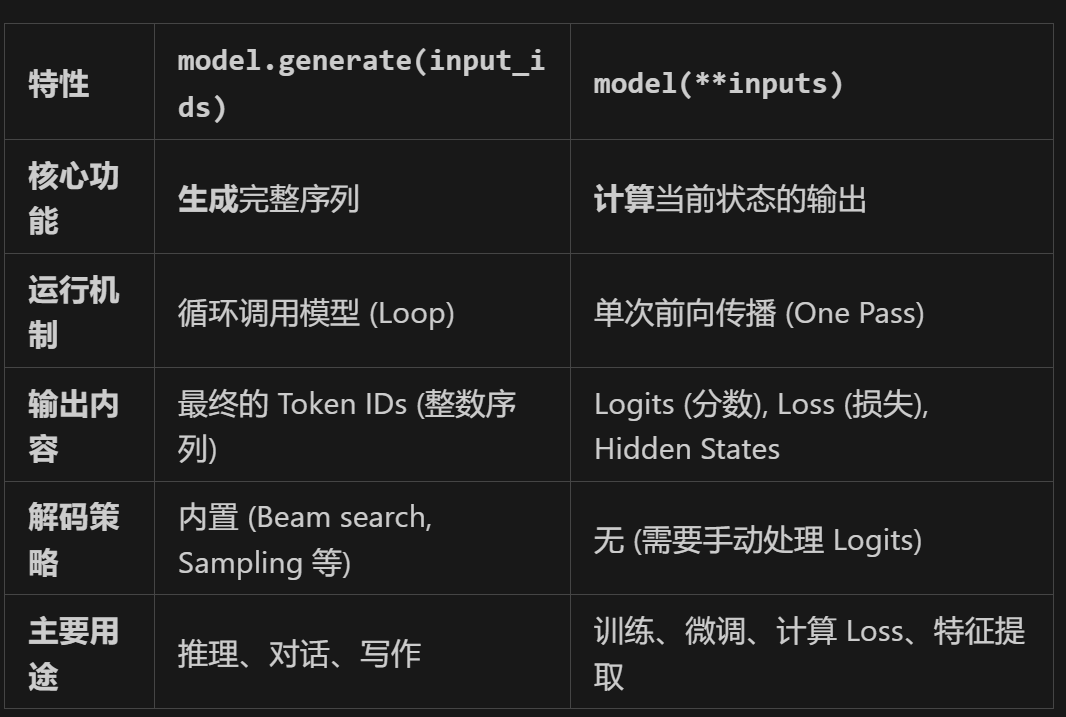

# 4. Pipeline
## 4.1 什么是Pipeline

**Pipeline**:将数据预处理、模型调用、结果后处理三部分组装成的流水线，使我们能够直接输入文本便获得最终的答案
<br>

<img src="images/image-20240712150115099.png"  />





## 4.2 Pipeline支持的任务类型

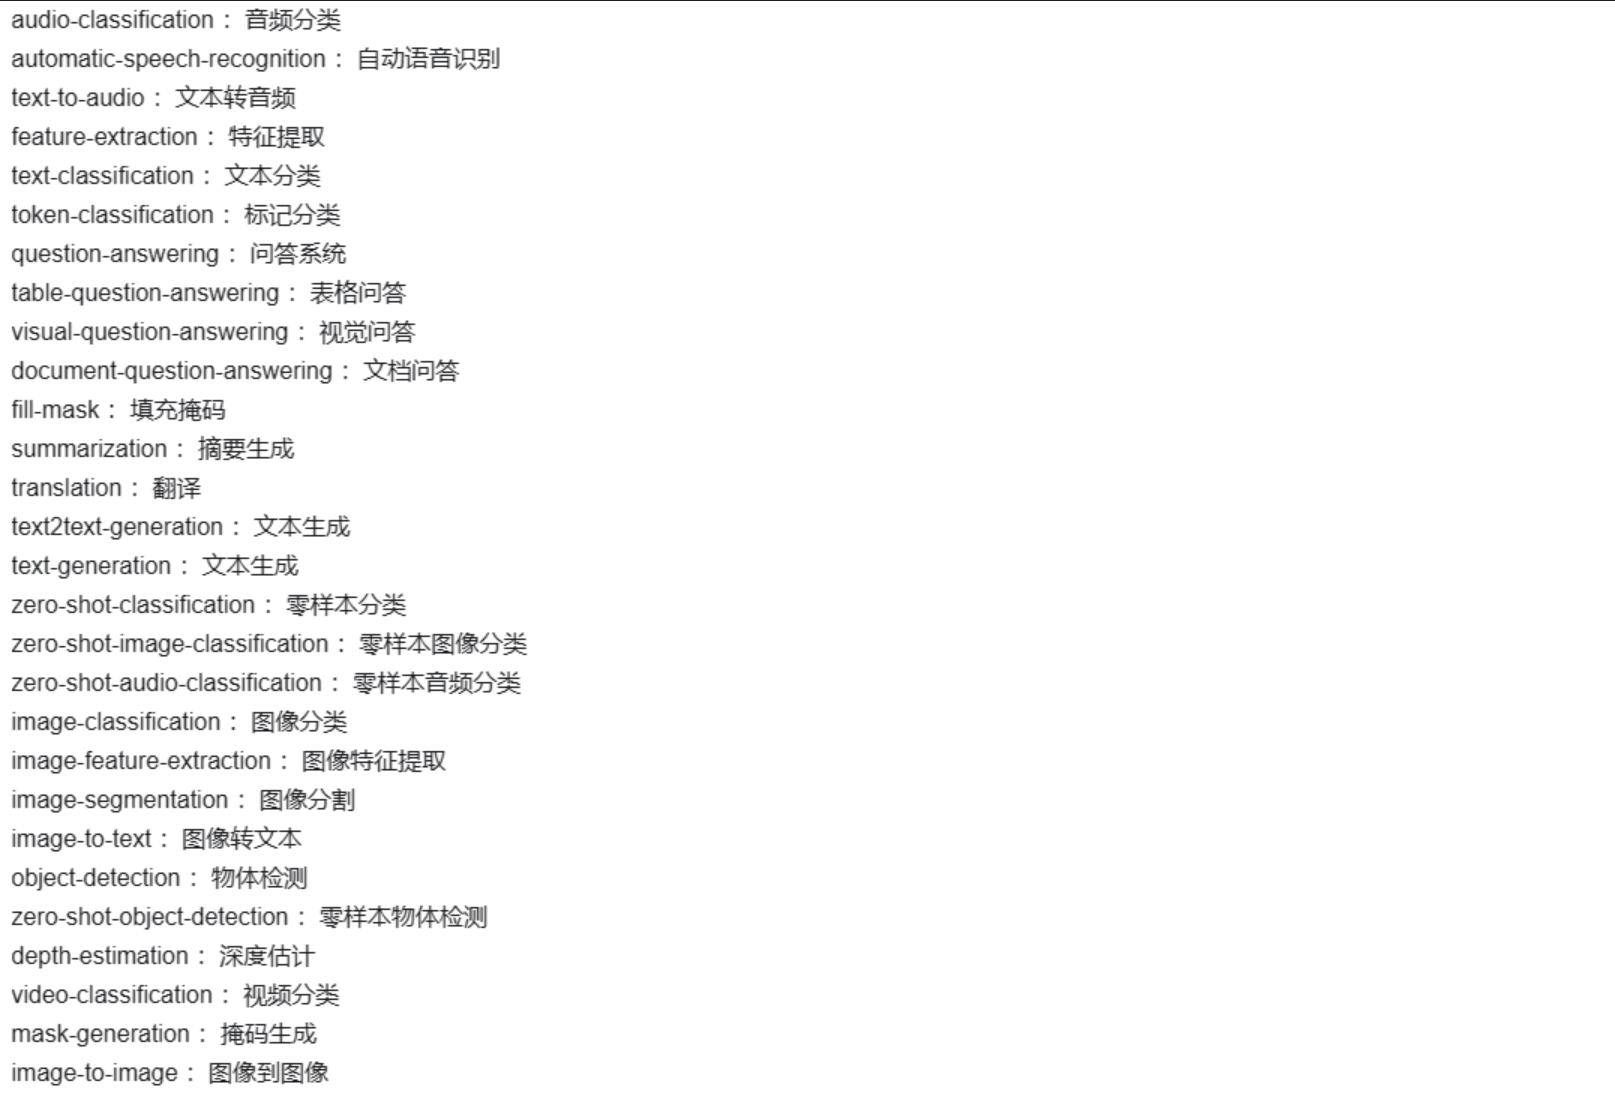

## 4.3 Pipeline的创建与使用方式

### 1) 基本使用

In [ ]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer, pipeline

# 1、根据任务类型直接创建Pipeline  默认会去加载这个模型：distilbert-base-uncased-finetuned-sst-2-english
# 需要外网一定要畅通
# pipe = pipeline("text-classification") 

# 2、指定任务类型，再指定模型，创建基于指定模型的Pipeline
# pipe = pipeline("text-classification", model="uer-roberta-base-finetuned-dianping-chinese")
# pipe("我觉得不太行！")

# 3、预先加载模型，再创建Pipeline
model = AutoModelForSequenceClassification.from_pretrained("/teacher_train/model/roberta-base-finetuned-dianping-chinese/")
tokenizer = AutoTokenizer.from_pretrained("/teacher_train/model/roberta-base-finetuned-dianping-chinese/")
pipe = pipeline("text-classification",model=model, tokenizer=tokenizer)
print(pipe("真术相成真的很好"))

### 2) 使用GPU进行推理加速

cpu上的推理肯定没有gpu上的快，那么有多慢呢？我们可以做一个实验：做100次 文本分类任务，"我觉得不太行!"，求得一个平均时间

In [ ]:
import torch
import time
from transformers import pipeline

pipe = pipeline("text-classification", 
model="models/roberta-base-finetuned-dianping-chinese",device=0)
print(pipe.model.device)

times =[]
for i in range(100):
    torch.cuda.synchronize()
    start = time.time()
    pipe("真术相成真的很好!")
    torch.cuda.synchronize()
    end = time.time()
    times.append(end - start)
print(sum(times)/100)

### 3) Pipeline处理检测模型

Task：zero-shot-object-detection  0样本目标检查
<br>
Model：google/owlvit-base-patch32  谷歌图片识别模型
<br>

In [ ]:
from transformers import *
from PIL import Image, ImageDraw

# 加载模型
checkpoint=r"/teacher_train/model/owlvit-base-patch32/"
detecter = pipeline(model=checkpoint, task='zero-shot-object-detection')

path = "/teacher_data/wtb/教学文档/大模型教学文档/large_model/bigmodel/02-huggingface/pic1.jpg"
image = Image.open(path)

# 侦测
predictions = detecter(image, candidate_labels=['cat'])			
print(predictions)

# 后处理
draw = ImageDraw.Draw(image)	
	
for prediction in predictions:	
    box = prediction['box']	
    label = prediction['label']	
    score = prediction['score']	
    xmin, ymin, xmax, ymax = box.values()	
    draw.rectangle((xmin, ymin, xmax, ymax), outline='red', width=1)	
    draw.text((xmin, ymin), f"{label}:  {round(score, 2)}", fill='red')	

image.save("result.jpg")

### 4) Pipeline处理检测模型

In [ ]:
from transformers import *
import torch

# 初始化Tokenizer和Model （加载组件）
path = r'D:\vs_code\transformers-code\models\uer\roberta-base-finetuned-dianping-chinese'
tokenizer = AutoTokenizer.from_pretrained(path)
model = AutoModelForSequenceClassification.from_pretrained(path)

# 数据预处理
input_text="真术相成真的很好!"
#‘pt’: 返回PyTorch的张量对象torch.Tensor
inputs = tokenizer(input_text, return_tensors="pt") 
print(inputs)

# 模型预测
res = model(**inputs) #将inputs解包 模型只接受关键字参数而不是字典
print(res)

logits = res.logits
logits = torch.softmax(logits, dim=-1)
print(logits)

# 结果后处理
pred = torch.argmax(logits).item()
print(pred)

result = model.config.id2label.get(pred)
print(result)


# 文本分类任务

任务类型：文本分类<br>

使用模型：hfl/rbt3<br>

数据集地址： https://github.com/SophonPlus/ChineseNlpCorpus
<br>
这个CSV文件中：label 标签 1是好评、0是差评；  review具体的评论。<br>
是一个比较简单的数据集，那么我们怎么从0开始写（只用tokenizer和model）文本分类的方案。<br>

代码参考：[text](other_files/cls_model.ipynb)

# 5.Datasets
## 5.1 Datasets简介

datasets库是一个非常简单易用的数据集加载库，可以方便快捷的从本地或者HuggingFace Hub加载数据集
<br>
公开数据地址：https://huggingface.co/datasets 
<br>
文档地址：https://huggingface.co/docs/datasets/index
<br>

![image.png](images/1720775182710.jpg)

<br>
Datasets下面有很多的数据集，我们可以有选择的去加载我们想要的数据集
<br>


## 5.2 Datasets加载本地数据集
### 1) 直接加载文件作为数据集

In [ ]:
from datasets import *

# 加载csv中所有的数据
dataset = load_dataset("csv", data_files="./ChnSentiCorp_htl_all.csv")
dataset

#可用的构建器包括："json", "csv", "parquet", "arrow", "text", 
# "xml", "webdataset", "imagefolder", "audiofolder", "videofolder"


### 2) 加载的数据作为训练集

In [ ]:
dataset = load_dataset("csv", data_files="./ChnSentiCorp_htl_all.csv", split='train')
print(dataset)


### 3) 加载文件夹内全部文件作为数据集
![image.png](images/image.png)


In [ ]:
# 加载指定文件夹下面的所有csv文件
dataset = load_dataset("csv", data_dir='./all_data/', split='train')
print(dataset)

In [ ]:
# 加载多个单独的csv文件
dataset = load_dataset("csv", data_files=['./all_data/ChnSentiCorp_htl_all.csv', './all_data/ChnSentiCorp_htl_all copy.csv'], split='train')
dataset

### 4) load_dataset 加载后的数据格式

In [ ]:
"""
# 传统 Python 列表存储
data = [
    {"Question": "问题1", "CoT": "思维1", "Response": "答案1"},
    {"Question": "问题2", "CoT": "思维2", "Response": "答案2"},
    {"Question": "问题3", "CoT": "思维3", "Response": "答案3"}
]

Arrow 列式存储 (Columnar Storage)  类似于我们的excel表

Question列:  [0x1000] [0x1008] [0x1010]
             问题1    问题2    问题3     ← 连续存储

CoT列:       [0x2000] [0x2008] [0x2010]
             思维1    思维2    思维3     ← 连续存储

Response列:  [0x3000] [0x3008] [0x3010]
             答案1    答案2    答案3     ← 连续存储
"""

### 5) 划分训练集与测试集

In [ ]:
data = datasets['train']  # 加载训练集 5850条
data.train_test_split(test_size=0.1)

### 6) 数据选取和过滤

In [ ]:
datasets['train'].select([0, 1, 2])  #选取前3条数据

data = dataset.filter(lambda x: x['review'] is not None)  #过滤掉review为None的数据

### 7) data.map 数据整理

In [ ]:
from datasets import load_dataset
from transformers import AutoModelForSequenceClassification,AutoTokenizer

path = path = "/teacher_train/model/roberta-base-finetuned-dianping-chinese/"

# model = AutoModel.from_pretrained(path)
tokenizer = AutoTokenizer.from_pretrained(path)

model = AutoModelForSequenceClassification.from_pretrained(path)
dataset = load_dataset("csv",data_files="/teacher_data/wtb/教学文档/大模型教学文档/large_model/bigmodel/02-huggingface/ChnSentiCorp_htl_all.csv",split="train")

data = dataset.filter(lambda x: x['review'] is not None)

split_data = data.train_test_split(test_size=0.2)

def preprocess_function(examples):  #数据处理函数
    model_input = tokenizer(examples['review'], max_length=128, truncation=True)
    # model_input['labels'] = examples['label']
    # print(model_input)
    return model_input


train_data = split_data['train'].map(preprocess_function, batched=True,remove_columns='review')

test_data = split_data['test'].map(preprocess_function, batched=True,remove_columns='review')

### 8) 保存与加载处理好的数据

In [ ]:
from datasets import load_from_disk

# 保存处理后的数据 经过dataset.map处理过后的数据
processed_data.save_to_disk("./processed_data")

# load_from_disk
# 用于加载任何 save_to_disk 保存的数据
# 不需要指定格式，因为元数据已经保存了
dataset = load_from_disk("/path/to/saved_dataset")

## 5.3 DataCollatorWithPadding

DataCollator类，该类用于将数据集的单个元素打包成一批数据。
<br>
DataCollatorWithPadding类是DataCollator类的一个实现类，该类在打包时将动态填充输入的数据。
<br>
- 参数tokenizer表示输入的分词器。
- 参数padding可以为bool类型，True表示填充，False表示不填充；也可以为字符串，表示填充策略，longest表示根据输入数据中最长的数据来进行填充，max_length表示填充至参数max_length设置的长度，“do_not_pad"表示不填充。
- 参数pad_to_multiple_of表示填充的数据的倍数。		
- 参数return_tensors表示返回的数据类型，可以为"pt”，pytorch数据类型；“tf”，tensorflow数据类型；“np”，"numpy"数据类型。	

In [ ]:
# Dataset with DataCollator	
from transformers import DataCollatorWithPadding, AutoTokenizer
from datasets import load_dataset
from torch.utils.data import DataLoader


dataset = load_dataset("csv", data_files='./ChnSentiCorp_htl_all.csv', split='train')	
dataset = dataset.filter(lambda x: x['review'] is not None)	

tokenizer = AutoTokenizer.from_pretrained(r'D:\vs_code\transformers-code\models\google-bert\bert-base-chinese')
	
# 对review字段进行处理，最大长度128，过长进行截断；过短就不填充，组成batch的时候动态填充就可以了	
def process_fun(examples):	
    tokenized_examples = tokenizer(examples['review'], max_length=128, truncation=True)	
    tokenized_examples['labels'] = examples['label']	
    return tokenized_examples	
	
tokenized_dataset = dataset.map(process_fun, batched=True, remove_columns=dataset.column_names)	
print(tokenized_dataset)	
print(tokenized_dataset[:3])

collator = DataCollatorWithPadding(tokenizer=tokenizer,
                                   padding=True, #按照批次补充到最长的那条数据的长度不受max_length影响
                                   max_length=512, #不会截断，当padding="max_length"，补充到定义到max_length=512的长度
                                   pad_to_multiple_of=8)#将序列扩展为8的倍数

dl = DataLoader(tokenized_dataset, batch_size=4, collate_fn=collator, shuffle=True)

num = 0	
for batch in dl:	
    print(batch['input_ids'].size())	
    num += 1	
    if num > 10:	
        break


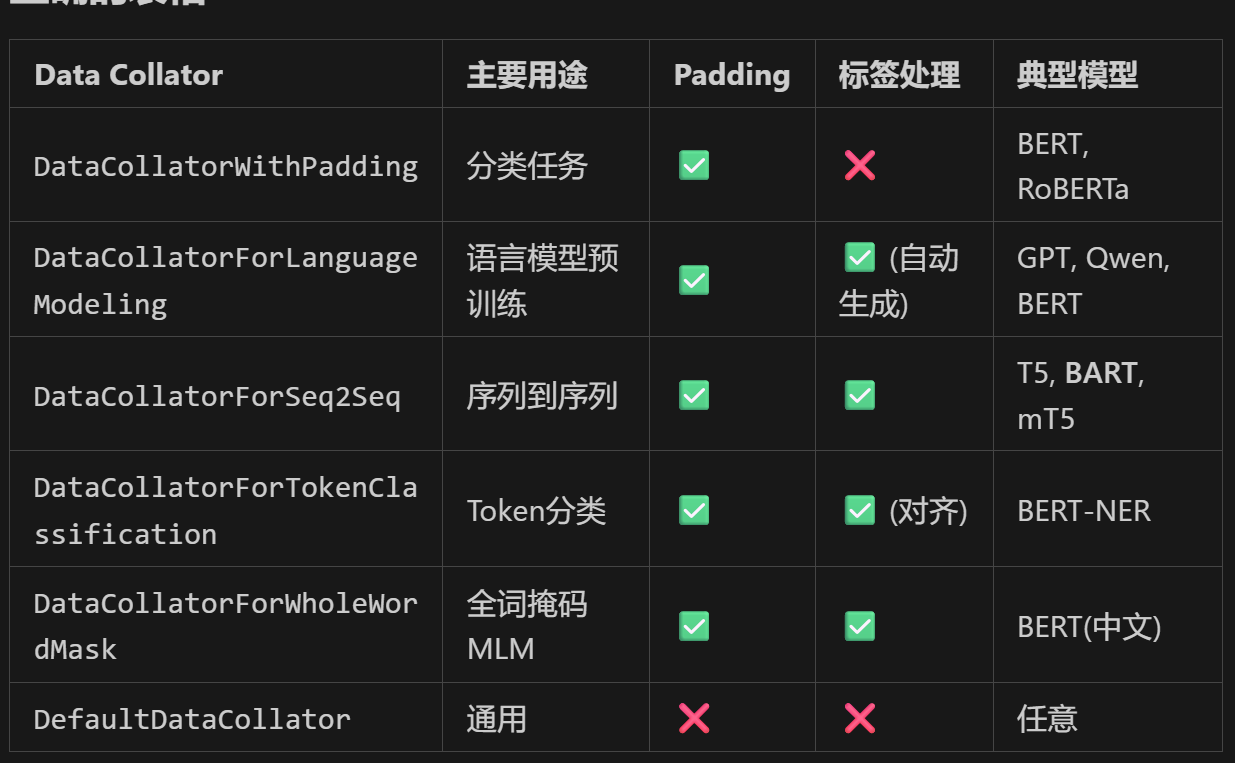

用于因果语言模型时： <br>
DataCollatorForLanguageModeling(<br>
    tokenizer=tokenizer,<br>
    mlm=False)<br>

mlm=False:<br>
它主要做两件事：<br>
不随机将 token 替换成 [MASK]<br>
直接复制 input_ids 构造 labels，不需要手动去定义labels<br>

例如：<br>
input_ids: [我, 喜, 欢, 学, 习, PAD]<br>
labels:    [我, 喜, 欢, 学, 习, -100]<br>


如果是 mlm=True，则用于 BERT：<br>
原始文本：我 喜 欢 学 习<br>
模型输入：我 [MASK] 欢 学 习<br>
labels：  -100 喜 -100 -100 -100<br>



DataCollatorForSeq2Seq<br>
需要的输入数据的格式<br>

{<br>
    "input_ids": tensor(...),<br>
    "attention_mask": tensor(...),<br>
    "labels": tensor(...)<br>
}<br>


当输入的模型是 Transformer架构<br>
{<br>
    "input_ids": ...,<br>
    "attention_mask": ...,<br>
    "labels": ...,<br>
    "decoder_input_ids": ...  #根据label错位得到的<br>
}<br>

当时decoder-only的时候<br>

{<br>
    "input_ids": tensor(...),   #作为decoder的输入<br>
    "attention_mask": tensor(...),<br>
    "labels": tensor(...)<br>
}<br>


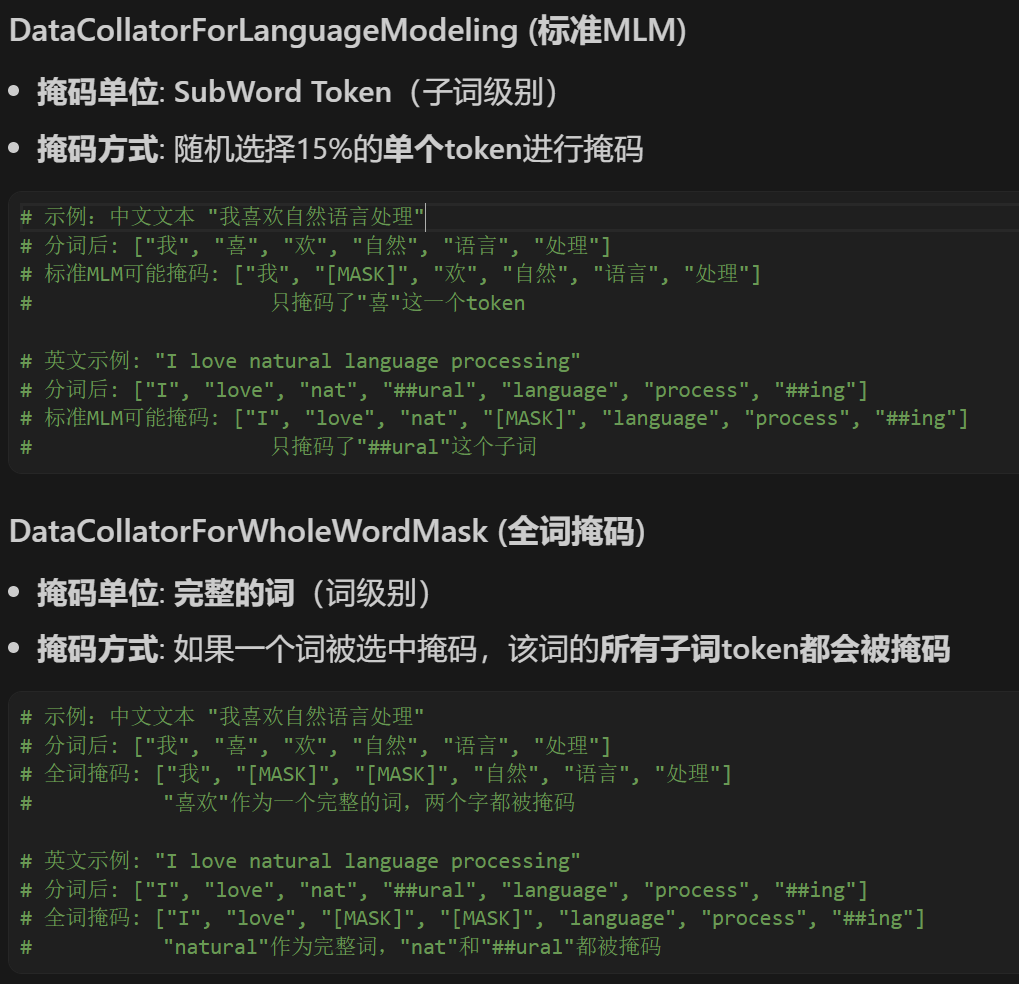

# 6. Evaluate
## 6.1 Evaluate简介
evaluate库是一个非常简单易用的机器学习模型评估函数库
<br>

只需要一行代码便可以加载各种任务的评估函数
<br>
函数库地址:https://huggingface.co/evaluate-metric
<br>
文档地址:https://huggingface.co/docs/evaluate/index
<br>
源代码:https://github.com/huggingface/evaluate

## 6.2 Evaluate基本使用

### 1) 查看支持的评估函数

In [ ]:
import os
os.environ['HF_ENDPOINT'] = 'https://hf-mirror.com'
import evaluate
#pip install scikit-learn

# 需要挂外网或者有镜像源
list_evaluate = evaluate.list_evaluation_modules(include_community=True, with_details=False)
print(list_evaluate)

查看支持的评估函数，到D:\vs_code\transformers-code\models\evaluate-main\metrics文件夹下查看

### 2) 加载评估函数

In [ ]:
import evaluate

accuracy = evaluate.load("accuracy")
print(accuracy.description)  # 评估函数的介绍
print(accuracy.inputs_description)# 包括参数、返回值、示例等介绍

### 3) 评估指标计算 

In [ ]:
# 1. 加载各个指标
accuracy = evaluate.load("accuracy")
precision = evaluate.load("precision")#精确率
recall = evaluate.load("recall") #召回率
f1 = evaluate.load("f1")

predictions = [1, 0, 1, 1]
references = [1, 0, 0, 1]

# 2. 分别计算
acc_result = accuracy.compute(predictions=predictions, references=references)
prec_result = precision.compute(predictions=predictions, references=references)
recall_result = recall.compute(predictions=predictions, references=references)
f1_result = f1.compute(predictions=predictions, references=references)


In [ ]:
# 迭代计算
accuracy = evaluate.load("accuracy")
for ref, pred in zip([0,1,0,1], [1,0,0,1]):
    accuracy.add(reference=ref, prediction=pred)
accuracy.compute()


{'accuracy': 0.5}

### 4) 计算多个评估指标

In [ ]:
import os
os.environ['HF_ENDPOINT'] = 'https://hf-mirror.com'
import evaluate

list_evaluate = evaluate.list_evaluation_modules(include_community=True, with_details=False)
print(list_evaluate)

# accuracy = evaluate.load("accuracy")
# results = accuracy.compute(references=[1, 0, 0, 0], predictions=[1, 1, 0, 0])
# print(results)

clf_metrics = evaluate.combine(["accuracy", "f1"])
results = clf_metrics.compute(references=[1, 0, 0, 0], predictions=[1, 1, 0, 0])
print(results)

### 5) 评估结果对比可视化

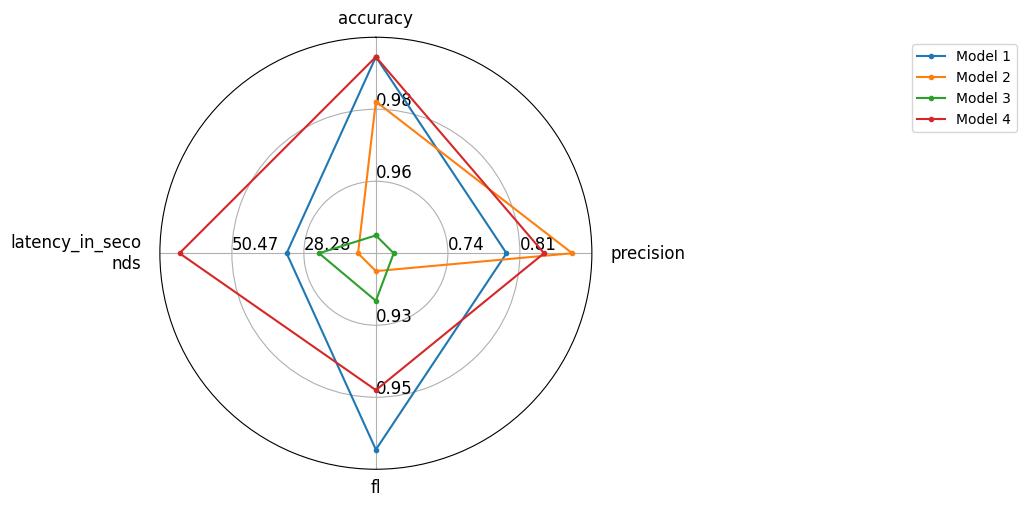

In [20]:
from evaluate.visualization import radar_plot  # 目前只支持雷达图

data = [
    {"accuracy": 0.99, 'precision':0.8, "fl":0.97, 'latency_in_seconds': 33.6},
    {"accuracy": 0.98, 'precision':0.87, "fl":0.91, 'latency_in_seconds': 11.6},
    {"accuracy": 0.95, 'precision':0.68, "fl":0.92, 'latency_in_seconds': 23.6},
    {"accuracy": 0.99, 'precision':0.84, "fl":0.95, 'latency_in_seconds': 66.6}
]
model_name = ['Model 1', 'Model 2', 'Model 3', 'Model 4']

plot = radar_plot(data=data, model_names=model_name)


# 7. Trainer
## 7.1 Trainer简介	
Trainer是transformers库中提供的训练的函数，内部封装了完整的训练、评估逻辑，并集成了多种<br>
的后端，如DeepSpeed、Pytorch FSDP等，搭配TrainingArguments对训练过程中的各项参数进<br>
行配置，可以非常方便快捷地启动模型单机/分布式训练<br>
    <br>
需要注意的是：<br>
a 使用Trainer进行模型训练对模型的输入输出是有限制的，要求模型返回元组或者ModelOutput的子类<br>
b 如果输入中提供了labels，模型要能返回loss结果，如果是元组，要求loss为元组中第一个值<br>
    <br>
文档地址：<br>
https://huggingface.co/docs/transformers/main_classes/trainer#trainer


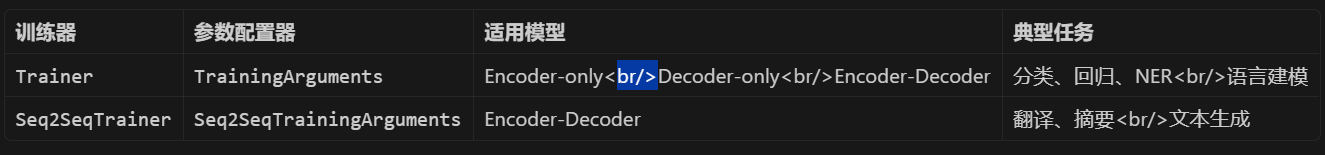


SFTTrainer、DPOTrainer、RewardTrainer、PPOTrainer 这些训练器：
来自 TRL (Transformer Reinforcement Learning) 库，不是 transformers 核心库

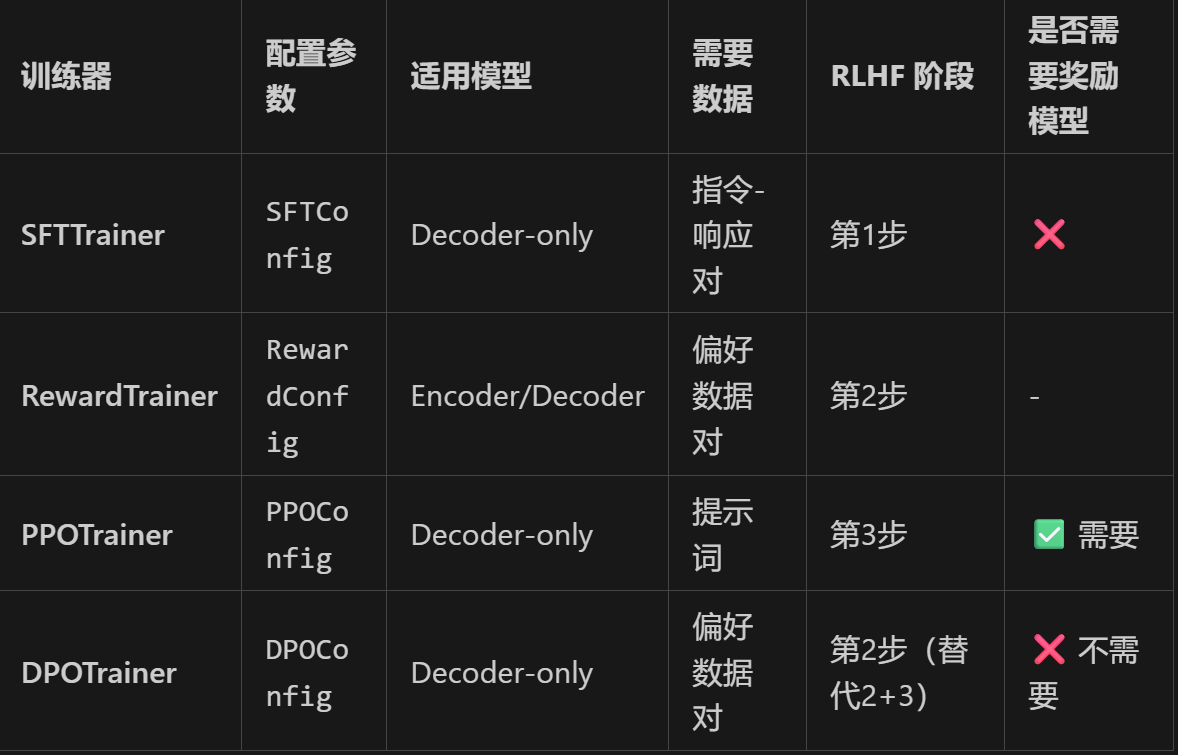


<br>

## 7.2 TrainingArguments + Trainer代码优化
任务类型：文本分类
<br>
使用模型：hfl/rbt3
<br>
数据集地址： https://github.com/SophonPlus/ChineseNlpCorpus
<br>


代码参考：[text](other_files/cls_Trainer-微调-最终版.ipynb)

In [ ]:
train_args = TrainingArguments(
    
    # ==================== 基础设置 ====================
    output_dir="./checkpoints",                    # 模型预测和检查点输出的目录（必填）
    overwrite_output_dir=True,                      # 是否覆盖已存在的输出目录内容
    
    # ==================== 训练控制 ====================
    do_train=True,                                 # 是否运行训练
    do_eval=True,                                  # 是否在验证集上评估
    do_predict=False,                              # 是否在测试集上运行预测
    
    # ==================== 批次大小 ====================
    per_device_train_batch_size=16,                # 每个 GPU/TPU 核心/CPU 的训练批次大小
    per_device_eval_batch_size=16,                 # 每个 GPU/TPU 核心/CPU 的评估批次大小
    gradient_accumulation_steps=1,                  # 在执行反向/更新前累积梯度的更新步数
    eval_accumulation_steps=None,                  # 在移动到 CPU 前累积预测的步数


    #Trainer 内部会在 get_train_dataloader() 里用 PyTorch DataLoader 把数据 按 batch 取出
    # 总的训练的样本数= per_device_train_batch_size × gradient_accumulation_steps × GPU数

    # ==================== 优化器参数 ====================
    learning_rate=2e-5,                            # AdamW 优化器的初始学习率
    weight_decay=0.01,                             # 权重衰减（L2 正则化），应用于除 bias 和 LayerNorm 外的所有层
    adam_beta1=0.9,                                # AdamW 优化器的 beta1 超参数
    adam_beta2=0.999,                              # AdamW 优化器的 beta2 超参数
    adam_epsilon=1e-8,                             # AdamW 优化器的 epsilon 超参数
    max_grad_norm=1.0,                             # 梯度裁剪的最大梯度范数
    adafactor=False,                               # 是否使用 Adafactor 优化器替代 AdamW
    
    # ==================== 训练轮次和步数 ====================
    num_train_epochs=10,                           # 要执行的训练轮数
    max_steps=-1,                                  # 总训练步数（如果为正数，会覆盖 num_train_epochs）
    
    # ==================== 学习率调度 ====================
    lr_scheduler_type="linear",                    # 学习率调度器类型："linear", "cosine", "constant", "polynomial" 等
    warmup_ratio=0.1,                              # 用于从 0 到 learning_rate 线性 warmup 的训练步数比例
    warmup_steps=0,                                # 用于从 0 到 learning_rate 线性 warmup 的步数（会覆盖 warmup_ratio）
    
    # ==================== 评估策略 ====================
    eval_strategy="epoch",                         # 评估策略："no", "steps", "epoch"
    eval_steps=None,                               # 当 eval_strategy="steps" 时，两次评估之间的更新步数
    prediction_loss_only=False,                    # 评估和生成预测时是否只返回损失
    
    # ==================== 日志记录 ====================
    logging_dir=None,                              # TensorBoard 日志目录，默认为 runs/**CURRENT_DATETIME_HOSTNAME**
    logging_strategy="steps",                      # 日志策略："no", "epoch", "steps"
    logging_first_step=False,                      # 是否记录和评估第一个 global_step
    logging_steps=500,                             # 当 logging_strategy="steps" 时，两次日志之间的更新步数
    report_to="all",                               # 上报平台列表："wandb", "tensorboard", "mlflow", "azure_ml", "comet_ml" 等
    run_name=None,                                 # 运行描述符，通常用于 wandb 日志记录
    disable_tqdm=None,                             # 是否禁用 tqdm 进度条
    
    # ==================== 保存策略 ====================
    save_strategy="steps",                         # 检查点保存策略："no", "epoch", "steps"
    save_steps=500,                                # 当 save_strategy="steps" 时，两次保存之间的更新步数
    save_total_limit=None,                         # 如果设置，将限制检查点总数，删除 output_dir 中较旧的检查点
    save_safetensors=True,                         # 是否使用 safetensors 格式保存模型
    
    # ==================== 模型选择 ====================
    load_best_model_at_end=False,                  # 训练结束时是否加载最佳模型
    metric_for_best_model=None,                    # 用于比较不同模型的指标名称（如 "loss", "accuracy"）
    greater_is_better=None,                        # 指标是否越大越好（loss 为 False，accuracy 为 True）
    
    # ==================== 设备相关 ====================
    no_cuda=False,                                 # 即使 CUDA 可用也不使用
    fp16=False,                                    # 是否使用 16 位（混合）精度训练替代 32 位训练
    fp16_opt_level="O1",                           # fp16 训练的 Apex AMP 优化级别："O0", "O1", "O2", "O3"
    fp16_backend="auto",                           # 混合精度训练的后端："auto", "amp", "apex"
    fp16_full_eval=False,                          # 评估时是否使用完整 16 位精度（更快但可能影响指标）
    bf16=False,                                    # 是否使用 bf16（bfloat16）混合精度训练
    bf16_full_eval=False,                          # 评估时是否使用完整 bf16 精度
    local_rank=-1,                                 # 分布式训练时的进程 rank
    tpu_num_cores=None,                            # TPU 训练时的 TPU 核心数
    debug=False,                                   # TPU 训练时是否打印调试指标
    
    # ==================== 数据加载 ====================
    dataloader_drop_last=False,                    # 是否丢弃最后一个不完整的批次
    dataloader_num_workers=0,                      # 数据加载的子进程数（PyTorch），0 表示在主进程加载
    dataloader_pin_memory=True,                    # 是否在数据加载器中固定内存
    remove_unused_columns=True,                    # 是否自动移除数据集中未使用的列
    label_names=None,                              # 输入字典中对应标签的键列表
    group_by_length=False,                         # 是否将训练数据集中长度相近的样本分组（减少 padding，提高效率）
    
    # ==================== 其他训练参数 ====================
    seed=42,                                       # 训练开始时的随机种子
    past_index=-1,                                 # 某些模型（如 TransformerXL、XLNet）使用过去隐藏状态的索引
    ignore_skip_data=False,                        # 恢复训练时是否跳过 epoch 和批次以保持数据加载阶段一致
    label_smoothing_factor=0.0,                    # 标签平滑因子（0 表示无标签平滑）
    skip_memory_metrics=False,                     # 是否跳过将内存分析报告添加到指标中
    
    # ==================== 分布式训练 ====================
    sharded_ddp=False,                             # 使用 FairScale 的 Sharded DDP 训练（分布式训练）
    deepspeed=None,                                # 使用 DeepSpeed，值为其 json 配置文件的路径
    ddp_find_unused_parameters=None,                # 分布式训练时传递给 DistributedDataParallel 的 find_unused_parameters 标志值
    ddp_backend="nccl",                            # 分布式训练的后端："nccl", "gloo", "mpi"
    gradient_checkpointing=False,                   # 是否使用梯度检查点（减少内存占用，但增加训练时间）
)

在 Hugging Face Trainer（以及大多数训练框架）中，step 指的是一次参数更新（optimizer step），而不是一次前向/反向计算。这两者的区别主要来自梯度累积（gradient accumulation）：

没有梯度累积时（gradient_accumulation_steps=1）：每处理一个 batch 就做一次前向 + 反向 + 参数更新，此时 step 和前向/反向次数恰好一一对应，容易让人混淆。<br>
有梯度累积时（比如 gradient_accumulation_steps=4）：Trainer 会连续做 4 次前向/反向，把梯度累加起来，然后才调用一次 optimizer.step() 更新参数。这才算 1 个 step。

In [ ]:
import os
os.environ['HF_ENDPOINT'] = 'https://hf-mirror.com'
os.environ['CUDA_VISIBLE_DEVICES'] = '0'  # 只用 0 号卡；要第 1 张就写成 '1'

from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                       AutoModel, DataCollatorWithPadding,AutoConfig)
from datasets import load_dataset
import datasets
import torch
from transformers import Trainer, TrainingArguments
import evaluate
import numpy as np


tokenizer = AutoTokenizer.from_pretrained(r'/teacher_train/model/rbt3/')
model = AutoModelForSequenceClassification.from_pretrained(r'/teacher_train/model/rbt3/')

dataset = load_dataset("csv", data_dir=r'/teacher_train/data/AiNiklaus/ChnSentiCorp/',split='train')
datasets = dataset.train_test_split(test_size=0.2)


def preprocess_fun(example):
    # 同时处理 review 和 label，确保对齐
    reviews = example['review']
    labels = example['label']
    
    # 过滤掉 None 或空字符串的 review，同时过滤对应的 label
    valid_pairs = [(str(r), l) for r, l in zip(reviews, labels) 
                    if r is not None and len(str(r).strip()) > 0]
    
    if not valid_pairs:
        # 如果整个批次都无效，返回空结果
        return {'input_ids': [], 'attention_mask': []}
    
    valid_reviews, valid_labels = zip(*valid_pairs)
    
    # Tokenize 有效的 reviews
    model_input = tokenizer(list(valid_reviews), max_length=512, truncation=True)
    
    # 添加对应的 labels
    model_input['labels'] = list(valid_labels)
    return model_input

processed_data = datasets.map(preprocess_fun, batched=True,
                              remove_columns=dataset.column_names)


train_data = processed_data['train']
test_data = processed_data['test']

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
 
accuracy = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions =np.argmax(predictions,axis=-1)
    return accuracy.compute(predictions=predictions, references=labels)
    #必须啊返回字典格式，因为是根据metric_for_best_model="accuracy"来获取的参数

train_args = TrainingArguments(
    output_dir=r'/teacher_train/wtb/finetun/rbt3_finetu/cls_csv_trainer',
    eval_strategy="steps",
    eval_steps=100,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    save_strategy="steps",
    save_steps=100,
    save_total_limit=3,
    num_train_epochs=10,
    weight_decay=0.01,
    metric_for_best_model="accuracy",
    load_best_model_at_end=True,
    gradient_accumulation_steps=2,
)

trainer = Trainer(model=model, 
                 args=train_args, 
                 train_dataset=train_data, 
                 eval_dataset=test_data, 
                 data_collator=data_collator,
                 compute_metrics=compute_metrics)



trainer.train()

trainer.evaluate(test_data)

trainer.save_model()

# 8. 总结
- Pipeline：流水线，用于模型推理，封装了完整的推理逻辑，包括数据预处理、型预测及后处理
- Tokenizer：分词器，用于数据预处理，将原始文本输入转换为模型的输入，包括input ids、attention mask等
- Model：模型，用于加载、创建、保存模型，对Pytorch中的模型进行了封装，同时更好的支持预训练模型
- Datasets： 数据集，用于数据集加载与预处理，支持加载在线与本地的数据集，提供了数据集层面的处理方法
- Evaluate：评估函数，用于对模型的结果进行评估，支持多种任务的评估函数Trainer
- Trainer：训练器，用于模型训练、评估，支持丰富的配置选项，快速启动模型训练流程
